In [2]:
from langgraph.graph import StateGraph, START, MessagesState, END
from langgraph.checkpoint.postgres import PostgresSaver
from langchain_ollama import ChatOllama
from langchain_groq import ChatGroq
from langgraph.checkpoint.memory import InMemorySaver
from langchain.messages import RemoveMessage # ye use kiya jata hai message ko permanent delete karna k liye
from dotenv import load_dotenv

load_dotenv()

True

In [3]:
llm1 = ChatOllama(model="nemotron-3-nano:30b-cloud")
llm2 = ChatGroq(model="llama-3.3-70b-versatile")
llm3 = ChatOllama(model="smollm2:360m")

In [4]:
final_model = llm1.with_fallbacks(fallbacks=[llm2,llm3])

In [5]:
def chat(state: MessagesState):
    response = final_model.invoke(state["messages"])
    return {
        "messages": response
    }

def delete_old_messages(state: MessagesState):
    msgs = state["messages"]

    # if more than 10 msgs, delete earliest 6
    if len(msgs) > 10:
        to_remove = msgs[:6]
        return{
            "messages": [RemoveMessage(id=m.id) for m in to_remove]
        }

    return {}

In [6]:
workflow = StateGraph(MessagesState)
workflow.add_node("chat",chat)
workflow.add_node("cleanup",delete_old_messages)

# edge
workflow.add_edge(START,"chat")
workflow.add_edge("chat","cleanup")
workflow.add_edge("cleanup", END)

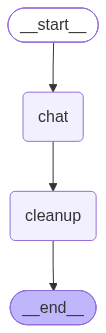

In [7]:
graph = workflow.compile(checkpointer=InMemorySaver())
graph

In [8]:
config = {
        "configurable": {
        "thread_id":"chat-1"
        }
    }

In [9]:

# Run multiple turns
graph.invoke({"messages": [{"role": "user", "content": "Hi, I'm Suman"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "Tell me about LangGraph"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "Now explain checkpointers"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is Langchain"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is Quantum Mechanics"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is Gen AI"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is my name"}]}, config)

{'messages': [HumanMessage(content='What is Langchain', additional_kwargs={}, response_metadata={}, id='f369cbc8-9fb2-4667-8562-159eb9a58a63'),
  AIMessage(content='### 🦜 LangChain at a Glance\n\n**LangChain** is an open-source framework for building applications powered by large language models (LLMs). Instead of writing monolithic prompts or hardcoded logic, it gives you standardized interfaces and modular "building blocks" so you can stitch together LLMs, prompts, tools, data sources, and logic like a Lego set.\n\nIt\'s language-agnostic in spirit (Python + JavaScript/TS editions) and is the most widely adopted ecosystem for going from LLM prototyping to production-grade systems.\n\n---\n\n### 🔧 Core Building Blocks\n| Block | What It Does |\n|------|--------------|\n| **LLMs & Embeddings** | Unified interface to OpenAI, Anthropic, Cohere, HuggingFace, etc. Also handles text embeddings for vector search. |\n| **Prompts** | Prompt templates that auto-fill variables, chat history form

In [10]:
snap = graph.get_state(config)
print("Stored messages after cleanup:", len(snap.values["messages"]))

Stored messages after cleanup: 8
